In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)

base = Path.cwd()

if not (base / "data" / "raw").is_dir():
    base = base.parent

if not (base / "data" / "raw").is_dir():
    raise FileNotFoundError(
        "Start Jupyter from the project root or notebooks folder."
    )

raw_file = (
    base
    / "data"
    / "raw"
    / "2024_LoL_esports_match_data_from_OraclesElixir.csv"
)

required_columns = [
    "gameid",
    "date",
    "league",
    "teamname",
    "position",
    "result",
]

df = pd.read_csv(
    raw_file,
    usecols=required_columns,
    low_memory=False,
)

print("Loaded:", raw_file.name)
print("Raw rows:", len(df))

display(df.head())

Loaded: 2024_LoL_esports_match_data_from_OraclesElixir.csv
Raw rows: 122448


,gameid,league,date,position,teamname,result
0,10660-10660_game_1,DCup,2024-01-01 05:13:15,top,LNG Esports,0
1,10660-10660_game_1,DCup,2024-01-01 05:13:15,jng,LNG Esports,0
2,10660-10660_game_1,DCup,2024-01-01 05:13:15,mid,LNG Esports,0
3,10660-10660_game_1,DCup,2024-01-01 05:13:15,bot,LNG Esports,0
4,10660-10660_game_1,DCup,2024-01-01 05:13:15,sup,LNG Esports,0


In [2]:
teams = df.loc[df["position"].eq("team")].copy()

required_team_fields = [
    "gameid",
    "date",
    "league",
    "teamname",
    "result",
]

# Normalize identification fields without changing capitalization.
for column in ["gameid", "league", "teamname"]:
    teams[column] = teams[column].astype("string").str.strip()
    teams[column] = teams[column].replace("", pd.NA)

# Invalid timestamps become missing and will be rejected below.
teams["date"] = pd.to_datetime(
    teams["date"],
    utc=True,
    errors="coerce",
)

# Invalid result values become missing and will also be rejected.
teams["result"] = pd.to_numeric(
    teams["result"],
    errors="coerce",
)

print("Team rows:", len(teams))
print("Earliest timestamp:", teams["date"].min())
print("Latest timestamp:", teams["date"].max())

print("\nMissing required fields:")
display(teams[required_team_fields].isna().sum())

print("\nResult values:")
display(teams["result"].value_counts(dropna=False))

display(teams.head())

Team rows: 20408
Earliest timestamp: 2024-01-01 05:13:15+00:00
Latest timestamp: 2024-12-08 09:03:13+00:00

Missing required fields:


gameid      0
date        0
league      0
teamname    0
result      0
dtype: int64


Result values:


result
0    10205
1    10203
Name: count, dtype: int64

,gameid,league,date,position,teamname,result
10,10660-10660_game_1,DCup,2024-01-01 05:13:15+00:00,team,LNG Esports,0
11,10660-10660_game_1,DCup,2024-01-01 05:13:15+00:00,team,Rare Atom,1
22,10660-10660_game_2,DCup,2024-01-01 06:03:26+00:00,team,LNG Esports,0
23,10660-10660_game_2,DCup,2024-01-01 06:03:26+00:00,team,Rare Atom,1
34,10660-10660_game_3,DCup,2024-01-01 06:54:35+00:00,team,LNG Esports,1


In [3]:
# Remove records identical on all fields needed by this pipeline.
before_deduplication = len(teams)

teams = teams.drop_duplicates(
    subset=required_team_fields
).copy()

exact_duplicates_removed = before_deduplication - len(teams)

# Rows without a game identifier cannot be assigned to a game.
missing_id_rows = teams.loc[teams["gameid"].isna()].copy()

identified = teams.loc[teams["gameid"].notna()].copy()

identified["required_fields_present"] = (
    identified[required_team_fields].notna().all(axis=1)
)

identified["valid_result"] = identified["result"].isin([0, 1])

game_checks = identified.groupby("gameid").agg(
    row_count=("teamname", "size"),
    unique_teams=("teamname", "nunique"),
    unique_dates=("date", "nunique"),
    unique_leagues=("league", "nunique"),
    total_wins=("result", "sum"),
    all_fields_present=("required_fields_present", "all"),
    all_results_binary=("valid_result", "all"),
)

# Separate reason columns make rejected games easier to investigate.
game_checks["bad_row_count"] = game_checks["row_count"].ne(2)
game_checks["bad_team_count"] = game_checks["unique_teams"].ne(2)
game_checks["bad_date_consistency"] = game_checks["unique_dates"].ne(1)
game_checks["bad_league_consistency"] = game_checks["unique_leagues"].ne(1)
game_checks["bad_winner_count"] = game_checks["total_wins"].ne(1)
game_checks["missing_required_fields"] = ~game_checks["all_fields_present"]
game_checks["nonbinary_results"] = ~game_checks["all_results_binary"]

reason_columns = [
    "bad_row_count",
    "bad_team_count",
    "bad_date_consistency",
    "bad_league_consistency",
    "bad_winner_count",
    "missing_required_fields",
    "nonbinary_results",
]

game_checks["valid"] = ~game_checks[reason_columns].any(axis=1)

valid_ids = game_checks.index[game_checks["valid"]]

teams_clean = identified.loc[
    identified["gameid"].isin(valid_ids),
    required_team_fields,
].copy()

rejected_games = game_checks.loc[~game_checks["valid"]].copy()

print("Duplicate team records removed:", exact_duplicates_removed)
print("Rows missing game ID:", len(missing_id_rows))
print("Accepted games:", len(valid_ids))
print("Rejected game groups:", len(rejected_games))

print("\nRejection reasons — a game can have multiple reasons:")
display(rejected_games[reason_columns].sum())

display(rejected_games.head(10))

Duplicate team records removed: 0
Rows missing game ID: 0
Accepted games: 10203
Rejected game groups: 1

Rejection reasons — a game can have multiple reasons:


bad_row_count              0
bad_team_count             0
bad_date_consistency       0
bad_league_consistency     0
bad_winner_count           1
missing_required_fields    0
nonbinary_results          0
dtype: int64

,row_count,unique_teams,unique_dates,unique_leagues,total_wins,all_fields_present,all_results_binary,bad_row_count,bad_team_count,bad_date_consistency,bad_league_consistency,bad_winner_count,missing_required_fields,nonbinary_results,valid
gameid,,,,,,,,,,,,,,,
LOLTMNT01_52116,2,2,1,1,0,True,True,False,False,False,False,True,False,False,False


In [4]:
ordered = teams_clean.sort_values(
    ["gameid", "teamname"]
).copy()

ordered["team_index"] = ordered.groupby("gameid").cumcount()

team_a = (
    ordered.loc[
        ordered["team_index"].eq(0),
        required_team_fields,
    ]
    .rename(
        columns={
            "date": "date_a",
            "league": "league_a",
            "teamname": "team_a",
            "result": "result_a",
        }
    )
)

team_b = (
    ordered.loc[
        ordered["team_index"].eq(1),
        required_team_fields,
    ]
    .rename(
        columns={
            "date": "date_b",
            "league": "league_b",
            "teamname": "team_b",
            "result": "result_b",
        }
    )
)

paired = team_a.merge(
    team_b,
    on="gameid",
    validate="one_to_one",
)

# Confirm opponent metadata agrees before discarding either copy.
assert paired["date_a"].eq(paired["date_b"]).all()
assert paired["league_a"].eq(paired["league_b"]).all()
assert paired["team_a"].ne(paired["team_b"]).all()
assert paired["result_a"].isin([0, 1]).all()
assert paired["result_b"].isin([0, 1]).all()
assert paired["result_a"].add(paired["result_b"]).eq(1).all()

matches = (
    paired.rename(
        columns={
            "gameid": "match_id",
            "date_a": "date",
            "league_a": "league",
        }
    )[
        [
            "match_id",
            "date",
            "league",
            "team_a",
            "team_b",
            "result_a",
        ]
    ]
    .sort_values(["date", "match_id"])
    .reset_index(drop=True)
)

matches["result_a"] = matches["result_a"].astype("int64")

assert matches["match_id"].is_unique
assert matches.notna().all().all()
assert matches["date"].is_monotonic_increasing
assert len(matches) == len(valid_ids)
assert len(teams_clean) == 2 * len(matches)

print("Final table shape:", matches.shape)
display(matches.head(10))

Final table shape: (10203, 6)


,match_id,date,league,team_a,team_b,result_a
0,10660-10660_game_1,2024-01-01 05:13:15+00:00,DCup,LNG Esports,Rare Atom,0
1,10660-10660_game_2,2024-01-01 06:03:26+00:00,DCup,LNG Esports,Rare Atom,0
2,10660-10660_game_3,2024-01-01 06:54:35+00:00,DCup,LNG Esports,Rare Atom,1
3,10660-10660_game_4,2024-01-01 07:35:57+00:00,DCup,LNG Esports,Rare Atom,0
4,10661-10661_game_1,2024-01-01 08:45:42+00:00,DCup,JD Gaming,Top Esports,1
5,10661-10661_game_2,2024-01-01 09:44:10+00:00,DCup,JD Gaming,Top Esports,0
6,10661-10661_game_3,2024-01-01 10:45:21+00:00,DCup,JD Gaming,Top Esports,1
7,10661-10661_game_4,2024-01-01 11:40:41+00:00,DCup,JD Gaming,Top Esports,0
8,10661-10661_game_5,2024-01-01 12:24:41+00:00,DCup,JD Gaming,Top Esports,1
9,10662-10662_game_1,2024-01-03 09:12:49+00:00,DCup,Bilibili Gaming,Ninjas in Pyjamas,1


source_file                     2024_LoL_esports_match_data_from_OraclesElixir...
raw_rows                                                                   122448
original_team_rows                                                          20408
exact_duplicate_rows_removed                                                    0
rows_missing_game_id                                                            0
rejected_game_groups                                                            1
accepted_games                                                              10203
competitions                                                                   53
unique_team_names                                                             517
earliest_game                                           2024-01-01 05:13:15+00:00
latest_game                                             2024-12-08 09:03:13+00:00
Name: value, dtype: object

Accepted games by competition:


league
LPL                717
LDL                565
LCKC               511
NACL               488
LCK                482
EM                 399
PCL                341
PCS                297
LEC                294
ESLOL              290
LAS                289
CBLOLA             276
CBLOL              263
VCS                252
LVP SL             242
PRM                241
LFL                237
LLA                213
NLC                208
LCS                192
TCL                181
LFL2               175
NEXO               160
UL                 159
HM                 155
LCO                154
LPLOL              154
GLL                153
AL                 152
EPL                151
LIT                149
LJL                148
EBL                142
PRMP               134
WLDs               132
HC                 115
TSC                107
LRS                102
LRN                 91
HW                  84
MSI                 78
NLC Aurora Open     77
CDF                 69
IC  

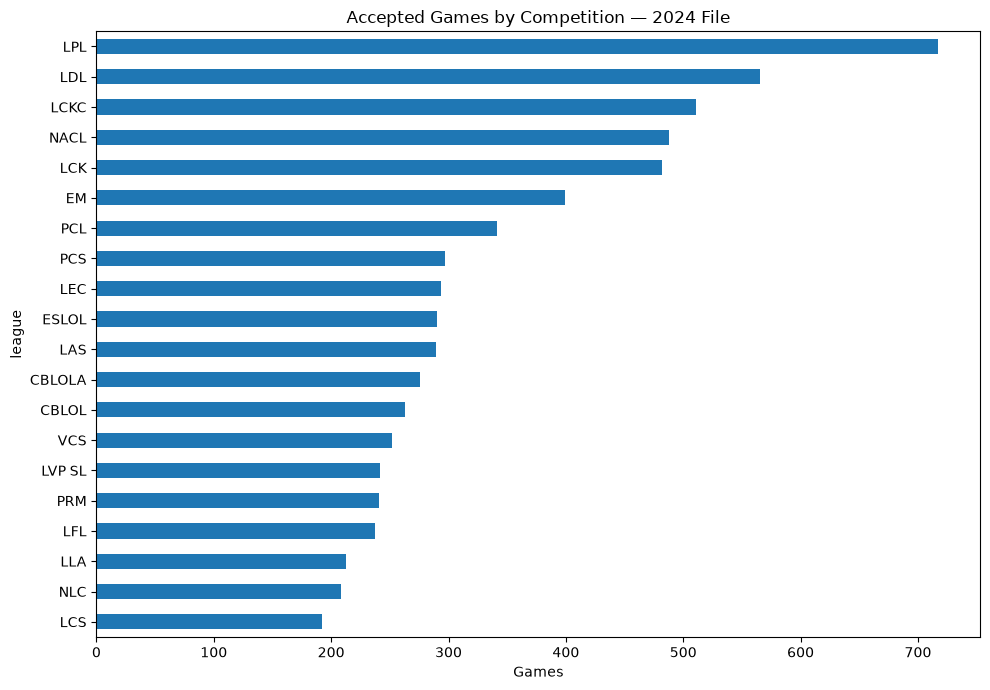

In [5]:
summary = pd.Series(
    {
        "source_file": raw_file.name,
        "raw_rows": len(df),
        "original_team_rows": before_deduplication,
        "exact_duplicate_rows_removed": exact_duplicates_removed,
        "rows_missing_game_id": len(missing_id_rows),
        "rejected_game_groups": len(rejected_games),
        "accepted_games": len(matches),
        "competitions": matches["league"].nunique(),
        "unique_team_names": pd.concat(
            [matches["team_a"], matches["team_b"]]
        ).nunique(),
        "earliest_game": matches["date"].min(),
        "latest_game": matches["date"].max(),
    },
    name="value",
)

display(summary)

league_counts = matches["league"].value_counts()

print("Accepted games by competition:")
display(league_counts)

league_counts.head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Accepted Games by Competition — 2024 File",
)

plt.xlabel("Games")
plt.tight_layout()
plt.show()

In [6]:
output_dir = base / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

matches.to_csv(
    output_dir / "matches_2024_clean.csv",
    index=False,
)

rejected_games.to_csv(
    output_dir / "matches_2024_rejected_games.csv",
    index=True,
)

missing_id_rows.to_csv(
    output_dir / "matches_2024_missing_id_rows.csv",
    index=False,
)

summary.to_csv(
    output_dir / "matches_2024_summary.csv",
    header=True,
)

print("Saved outputs to:", output_dir)

Saved outputs to: c:\Users\USER\lol_worlds_predictor\data\processed
